In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import json

np.random.seed(42)
NUM_USERS = 7867


## 1. Define questionnaire fields and profile categories

In [2]:
personality_qs = [
    "I am the life of the party.",
    "I get stressed out easily.",
    "I pay attention to details.",
    "I sympathize with others’ feelings.",
    "I have a rich vocabulary."
]

academic_qs = [
    "What is your CGPA range?",
    "Which stream are you studying?",
    "Do you prefer practical assignments over theory?"
]

skill_qs = [
    "Rate your logical reasoning ability.",
    "How do you rate your problem-solving skills.",
    "Rate your programming knowledge.",
    "How are your communication skills?",
    "Rate your creativity level."
]

personality_opts = ["Agree", "Neutral", "Disagree"]
cgpa_opts = ["<6", "6–8", "8–10"]
stream_opts = ["CSE", "ECE", "MECH", "CIVIL", "Other"]
practical_opts = ["Yes", "No", "Sometimes"]
skill_opts = ["Poor", "Average", "Good", "Excellent"]
programming_opts = ["Beginner", "Intermediate", "Expert"]

interest_opts = [
    "Software and Technology", "Data and Analytics", "Design and Creativity",
    "Business and Management", "People and Communication", "Finance",
    "Teaching and Research", "Engineering"
]
experience_opts = ["No experience", "Academic projects", "Internship", "Work experience"]
project_opts = ["None", "1–2 projects", "3–5 projects", "More than 5 projects"]
certification_opts = ["None", "1 certification", "2–3 certifications", "4+ certifications"]
career_preference_opts = [
    "Technical role", "Analytical role", "Creative role",
    "Management role", "People-focused role", "Independent work"
]
industry_opts = ["IT", "Finance", "Education", "Healthcare", "Manufacturing", "Media", "Any industry"]
work_environment_opts = ["Office", "Remote", "Hybrid", "Flexible"]
goal_opts = ["Entry-level job", "Specialist role", "Leadership role", "Higher studies", "Career change"]


## 2. Generate synthetic user profiles and assessment responses

In [3]:
n = NUM_USERS
data = {"user_id": np.arange(1, n + 1)}

# Career assessment responses
for q in personality_qs:
    data[q] = np.random.choice(personality_opts, n, p=[0.4, 0.3, 0.3])

data[academic_qs[0]] = np.random.choice(cgpa_opts, n, p=[0.1, 0.5, 0.4])
data[academic_qs[1]] = np.random.choice(stream_opts, n, p=[0.4, 0.2, 0.15, 0.15, 0.1])
data[academic_qs[2]] = np.random.choice(practical_opts, n, p=[0.45, 0.25, 0.30])

for q in skill_qs:
    if q == "Rate your programming knowledge.":
        data[q] = np.random.choice(programming_opts, n, p=[0.35, 0.45, 0.20])
    else:
        data[q] = np.random.choice(skill_opts, n, p=[0.15, 0.35, 0.35, 0.15])

# Initial user profile: interests, experience, and career preferences
data["Primary interest"] = np.random.choice(interest_opts, n)
data["Experience level"] = np.random.choice(experience_opts, n, p=[0.45, 0.25, 0.20, 0.10])
data["Projects completed"] = np.random.choice(project_opts, n, p=[0.25, 0.35, 0.25, 0.15])
data["Certifications"] = np.random.choice(certification_opts, n, p=[0.45, 0.30, 0.20, 0.05])
data["Preferred career type"] = np.random.choice(career_preference_opts, n)
data["Preferred industry"] = np.random.choice(industry_opts, n)
data["Preferred work environment"] = np.random.choice(work_environment_opts, n)
data["Career goal"] = np.random.choice(goal_opts, n)

df = pd.DataFrame(data)
df.head()


,user_id,I am the life of the party.,I get stressed out easily.,I pay attention to details.,I sympathize with others’ feelings.,I have a rich vocabulary.,What is your CGPA range?,Which stream are you studying?,Do you prefer practical assignments over theory?,Rate your logical reasoning ability.,...,How are your communication skills?,Rate your creativity level.,Primary interest,Experience level,Projects completed,Certifications,Preferred career type,Preferred industry,Preferred work environment,Career goal
0,1,Agree,Agree,Neutral,Agree,Neutral,8–10,CSE,Sometimes,Good,...,Average,Good,Business and Management,No experience,3–5 projects,1 certification,Analytical role,Manufacturing,Hybrid,Entry-level job
1,2,Disagree,Agree,Agree,Agree,Agree,8–10,Other,Sometimes,Average,...,Poor,Good,Software and Technology,Internship,1–2 projects,None,People-focused role,Education,Remote,Leadership role
2,3,Disagree,Agree,Agree,Disagree,Neutral,6–8,CSE,No,Excellent,...,Good,Good,Design and Creativity,No experience,More than 5 projects,None,People-focused role,Manufacturing,Remote,Leadership role
3,4,Neutral,Disagree,Disagree,Agree,Neutral,6–8,CSE,Yes,Good,...,Good,Excellent,People and Communication,No experience,3–5 projects,2–3 certifications,Creative role,Education,Remote,Career change
4,5,Agree,Agree,Agree,Neutral,Neutral,8–10,CSE,Yes,Poor,...,Average,Average,Business and Management,Academic projects,More than 5 projects,None,Independent work,Education,Flexible,Career change


## 3. Assign the synthetic career target

In [4]:
skill_rank = {"Poor": 0, "Average": 1, "Good": 2, "Excellent": 3}
prog_rank = {"Beginner": 0, "Intermediate": 1, "Expert": 2}
cgpa_rank = {"<6": 0, "6–8": 1, "8–10": 2}
personality_map = {"Agree": 1, "Neutral": 0, "Disagree": -1}
practical_map = {"Yes": 1, "Sometimes": 0, "No": -1}

def recommend_career(row):
    logical = skill_rank[row["Rate your logical reasoning ability."]]
    problem_solving = skill_rank[row["How do you rate your problem-solving skills."]]
    programming = prog_rank[row["Rate your programming knowledge."]]
    communication = skill_rank[row["How are your communication skills?"]]
    creativity = skill_rank[row["Rate your creativity level."]]
    cgpa = cgpa_rank[row["What is your CGPA range?"]]
    extraversion = personality_map[row["I am the life of the party."]]
    practical = practical_map[row["Do you prefer practical assignments over theory?"]]
    interest = row["Primary interest"]
    preference = row["Preferred career type"]
    stream = row["Which stream are you studying?"]

    if interest == "Teaching and Research" and communication >= 2:
        return "Teacher"
    if interest == "Finance" and logical >= 2 and creativity <= 2:
        return "Accountant"
    if interest == "Design and Creativity" and creativity >= 2:
        return "Graphic Designer"
    if interest == "People and Communication" and communication >= 2:
        return "HR Manager"
    if interest == "Business and Management" and communication >= 1:
        return "Project Manager"
    if programming >= 2 and logical >= 2:
        return "Software Engineer"
    if logical >= 2 and problem_solving >= 2 and (programming >= 1 or cgpa >= 1):
        return "Data Analyst"
    if programming >= 1 and creativity >= 2 and logical <= 2:
        return "Web Developer"
    if creativity >= 3 and communication >= 2:
        return "Marketing Specialist"
    if problem_solving >= 3 and communication >= 2 and cgpa >= 1:
        return "Business Analyst"
    if preference == "Analytical role" and logical >= 1:
        return "Data Analyst"
    if preference == "Creative role" and creativity >= 1:
        return "Graphic Designer"
    if practical == 1 and communication >= 1 and (cgpa >= 1 or logical >= 2):
        return "Project Manager"
    if stream == "CSE":
        return "Software Engineer"
    if stream == "ECE":
        return "Web Developer"
    if stream in ["MECH", "CIVIL"]:
        return "Project Manager"
    return "Consultant"

df["recommended_career"] = df.apply(recommend_career, axis=1)
df.head()


,user_id,I am the life of the party.,I get stressed out easily.,I pay attention to details.,I sympathize with others’ feelings.,I have a rich vocabulary.,What is your CGPA range?,Which stream are you studying?,Do you prefer practical assignments over theory?,Rate your logical reasoning ability.,...,Rate your creativity level.,Primary interest,Experience level,Projects completed,Certifications,Preferred career type,Preferred industry,Preferred work environment,Career goal,recommended_career
0,1,Agree,Agree,Neutral,Agree,Neutral,8–10,CSE,Sometimes,Good,...,Good,Business and Management,No experience,3–5 projects,1 certification,Analytical role,Manufacturing,Hybrid,Entry-level job,Project Manager
1,2,Disagree,Agree,Agree,Agree,Agree,8–10,Other,Sometimes,Average,...,Good,Software and Technology,Internship,1–2 projects,None,People-focused role,Education,Remote,Leadership role,Web Developer
2,3,Disagree,Agree,Agree,Disagree,Neutral,6–8,CSE,No,Excellent,...,Good,Design and Creativity,No experience,More than 5 projects,None,People-focused role,Manufacturing,Remote,Leadership role,Graphic Designer
3,4,Neutral,Disagree,Disagree,Agree,Neutral,6–8,CSE,Yes,Good,...,Excellent,People and Communication,No experience,3–5 projects,2–3 certifications,Creative role,Education,Remote,Career change,HR Manager
4,5,Agree,Agree,Agree,Neutral,Neutral,8–10,CSE,Yes,Poor,...,Average,Business and Management,Academic projects,More than 5 projects,None,Independent work,Education,Flexible,Career change,Project Manager


## 4. Explore the dataset

In [5]:
print("Dataset shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("Data type"))
display(df.isna().sum().to_frame("Missing values"))
display(df["recommended_career"].value_counts().to_frame("Records"))


Dataset shape: (7867, 23)


,user_id,I am the life of the party.,I get stressed out easily.,I pay attention to details.,I sympathize with others’ feelings.,I have a rich vocabulary.,What is your CGPA range?,Which stream are you studying?,Do you prefer practical assignments over theory?,Rate your logical reasoning ability.,...,Rate your creativity level.,Primary interest,Experience level,Projects completed,Certifications,Preferred career type,Preferred industry,Preferred work environment,Career goal,recommended_career
0,1,Agree,Agree,Neutral,Agree,Neutral,8–10,CSE,Sometimes,Good,...,Good,Business and Management,No experience,3–5 projects,1 certification,Analytical role,Manufacturing,Hybrid,Entry-level job,Project Manager
1,2,Disagree,Agree,Agree,Agree,Agree,8–10,Other,Sometimes,Average,...,Good,Software and Technology,Internship,1–2 projects,None,People-focused role,Education,Remote,Leadership role,Web Developer
2,3,Disagree,Agree,Agree,Disagree,Neutral,6–8,CSE,No,Excellent,...,Good,Design and Creativity,No experience,More than 5 projects,None,People-focused role,Manufacturing,Remote,Leadership role,Graphic Designer
3,4,Neutral,Disagree,Disagree,Agree,Neutral,6–8,CSE,Yes,Good,...,Excellent,People and Communication,No experience,3–5 projects,2–3 certifications,Creative role,Education,Remote,Career change,HR Manager
4,5,Agree,Agree,Agree,Neutral,Neutral,8–10,CSE,Yes,Poor,...,Average,Business and Management,Academic projects,More than 5 projects,None,Independent work,Education,Flexible,Career change,Project Manager


,Data type
user_id,int32
I am the life of the party.,object
I get stressed out easily.,object
I pay attention to details.,object
I sympathize with others’ feelings.,object
I have a rich vocabulary.,object
What is your CGPA range?,object
Which stream are you studying?,object
Do you prefer practical assignments over theory?,object
Rate your logical reasoning ability.,object


,Missing values
user_id,0
I am the life of the party.,0
I get stressed out easily.,0
I pay attention to details.,0
I sympathize with others’ feelings.,0
I have a rich vocabulary.,0
What is your CGPA range?,0
Which stream are you studying?,0
Do you prefer practical assignments over theory?,0
Rate your logical reasoning ability.,0


,Records
Project Manager,1868
Data Analyst,1306
Web Developer,1239
Software Engineer,984
Graphic Designer,818
Teacher,480
HR Manager,475
Accountant,393
Business Analyst,119
Consultant,108


## 5. Visualize career and profile distributions

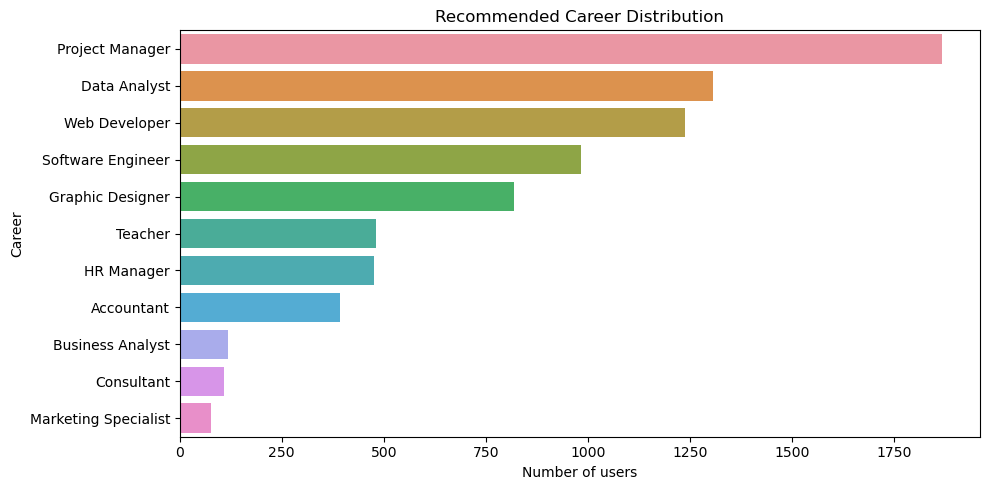

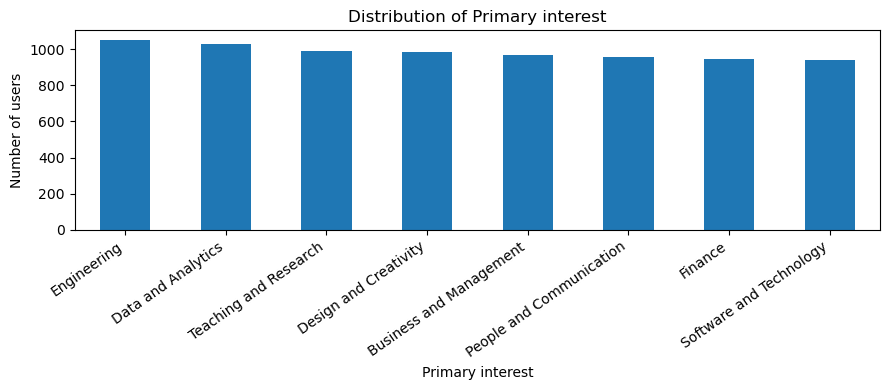

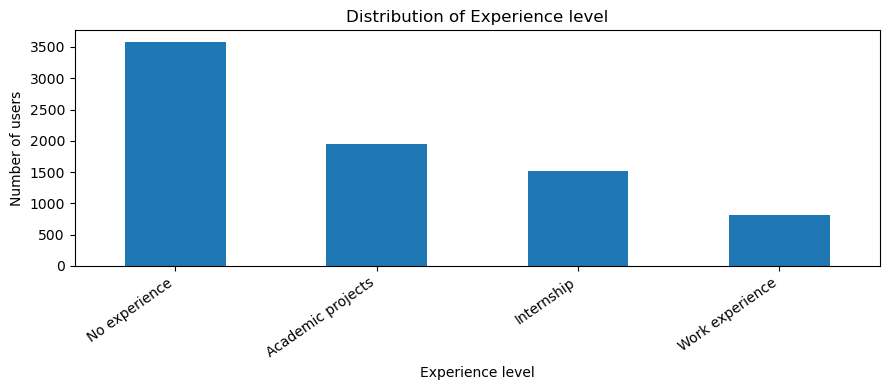

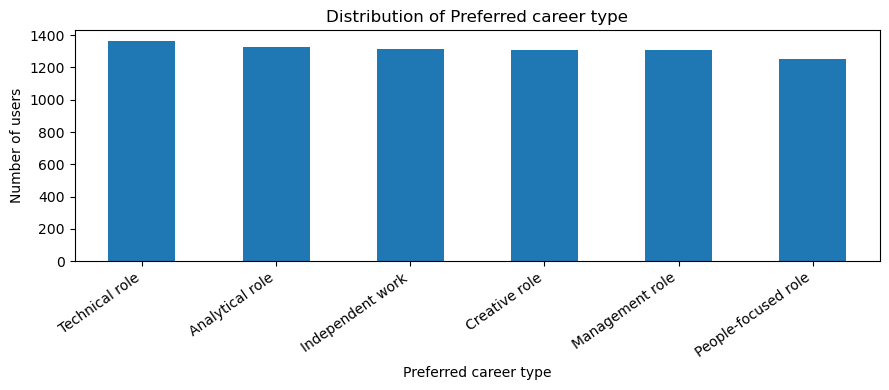

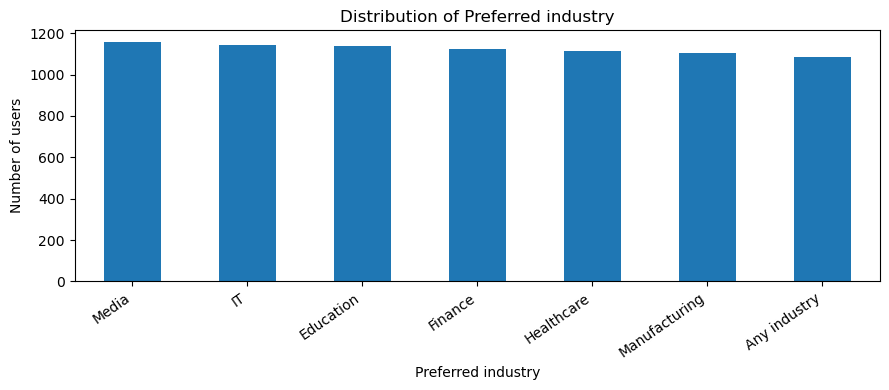

In [6]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y="recommended_career", order=df["recommended_career"].value_counts().index)
plt.title("Recommended Career Distribution")
plt.xlabel("Number of users")
plt.ylabel("Career")
plt.tight_layout()
plt.show()

for column in ["Primary interest", "Experience level", "Preferred career type", "Preferred industry"]:
    plt.figure(figsize=(9, 4))
    df[column].value_counts().plot(kind="bar")
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Number of users")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()


## 6. Prepare and encode model features

In [7]:
target_column = "recommended_career"
feature_columns = [column for column in df.columns if column not in ["user_id", target_column]]

# Explicit mappings keep the feature encoding consistent between training and application.
category_mappings = {}
encoded = df[feature_columns + [target_column]].copy()

for column in feature_columns:
    categories = sorted(encoded[column].dropna().unique().tolist())
    category_mappings[column] = {category: index for index, category in enumerate(categories)}
    encoded[column] = encoded[column].map(category_mappings[column])

target_classes = sorted(encoded[target_column].unique().tolist())
target_mapping = {career: index for index, career in enumerate(target_classes)}
encoded[target_column] = encoded[target_column].map(target_mapping)
encoded = encoded.astype("int64")

display(encoded.head())
print("Feature count:", len(feature_columns))
print("Encoded dataset shape:", encoded.shape)


,I am the life of the party.,I get stressed out easily.,I pay attention to details.,I sympathize with others’ feelings.,I have a rich vocabulary.,What is your CGPA range?,Which stream are you studying?,Do you prefer practical assignments over theory?,Rate your logical reasoning ability.,How do you rate your problem-solving skills.,...,Rate your creativity level.,Primary interest,Experience level,Projects completed,Certifications,Preferred career type,Preferred industry,Preferred work environment,Career goal,recommended_career
0,0,0,2,0,2,1,1,1,2,3,...,2,0,2,1,0,0,5,1,1,7
1,1,0,0,0,0,1,4,1,0,1,...,2,6,1,0,3,4,1,3,3,10
2,1,0,0,1,2,0,1,0,1,0,...,2,2,2,2,3,4,5,3,3,4
3,2,1,1,0,2,0,1,2,2,2,...,1,5,2,1,1,1,1,3,0,5
4,0,0,0,2,2,1,1,2,3,0,...,0,0,0,2,3,2,1,0,0,7


Feature count: 21
Encoded dataset shape: (7867, 22)


## 7. Save datasets and encoding mappings

In [10]:
df.to_csv("dataset/career_path_dataset.csv", index=False, encoding="utf-8-sig")
encoded.to_csv("dataset/career_path_dataset_encoded.csv", index=False, encoding="utf-8-sig")

mappings = {
    "feature_columns": feature_columns,
    "target_column": target_column,
    "feature_mappings": category_mappings,
    "target_mapping": target_mapping
}
with open("dataset/career_path_encoding_mappings.json", "w", encoding="utf-8") as file:
    json.dump(mappings, file, ensure_ascii=False, indent=2)

